In diesem Skript werden die Geotiffs von copernicus eingelesen, die mi einer 10x10 km resolution jeden Tag darstellen.
Damit kann verifiziert werden, ob die Downscalingdaten und die offiziellen CAMS Daten ähnliche Feinstaubwerte aufweisen.

In [12]:
import rasterio
import numpy as np

cams_path = r"C:\Users\AD\Desktop\Uni Würzburg\EAGLE\InnoLab\new_Output\Maps\ENS_ANALYSIS_reprojected.tif"

print("Röntgen-Scan der Copernicus-Datei startet...\n")

with rasterio.open(cams_path) as src:
    print("--- 1. METADATEN ---")
    print(f"Koordinatensystem (CRS): {src.crs}")
    print(f"Räumliche Ausdehnung:    {src.bounds}")
    print(f"Anzahl der Tage (Bänder): {src.count}")
    print(f"Datentyp der Pixel:      {src.dtypes[0]}")
    print(f"NoData-Wert:             {src.nodata}\n")

    # Wir lesen das allererste Band komplett ein (ohne Würzburg-Zuschnitt)
    band1 = src.read(1)

    print("--- 2. PIXEL-WERTE IN BAND 1 (1. Mai) ---")
    print(f"Niedrigster Wert:  {np.nanmin(band1)}")
    print(f"Höchster Wert:     {np.nanmax(band1)}")
    print(f"Durchschnitt:      {np.nanmean(band1)}")

Lade und filtere die neuen Kopfklinik-Daten...
-> 366 exakte 13-Uhr-Werte für die Kopfklinik gefunden.

Lade Masterdatei und ersetze die Werte für Sensor 1...

ERFOLG! Die reparierte Masterdatei liegt nun hier:
C:\Users\AD\Desktop\Uni Würzburg\EAGLE\InnoLab\Daten (Messstation WÜ)\Features_PM25_MASTER_FIXED.csv
-> Nutze ab sofort diese Datei für deine weiteren Modelle und Plots!


Schritt 1: Lade Daten & berechne Sensor-Zeitreihen...
Schritt 2: Trainiere RF-Modell auf lückenlosen Tagen...
Schritt 3: Generiere räumliches Raster...
Schritt 4: Starte täglichen Vorhersage-Loop...
Schritt 5: Erstelle umfassenden Zeitreihen-Plot...


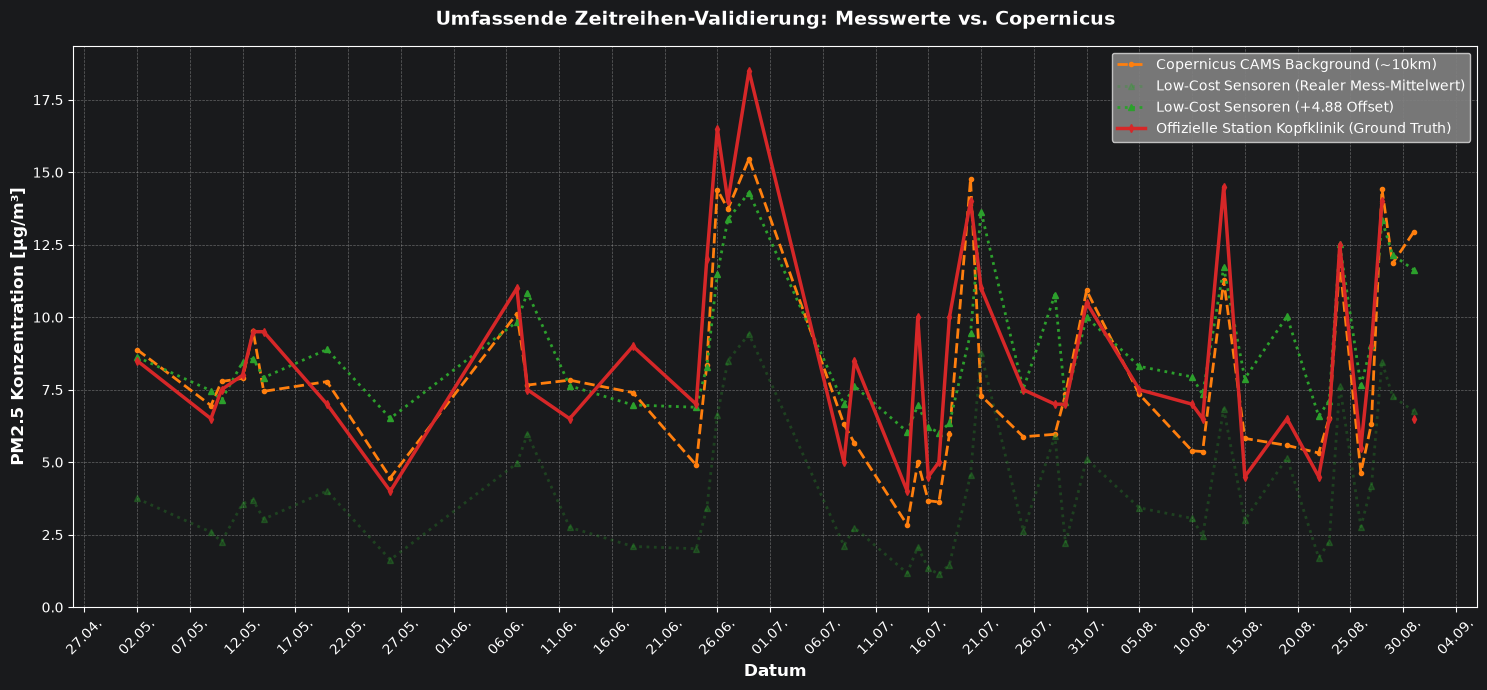

-> Das finale Validierungsdiagramm wurde gespeichert unter:
   C:\Users\AD\Desktop\Uni Würzburg\EAGLE\InnoLab\new_Output\RF_vs_Copernicus_vs_Sensors_Validation.png


In [22]:
import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings('ignore')

# =========================================================
# 1. Pfade & Einstellungen
# =========================================================
base_dir = r"C:\Users\AD\Desktop\Uni Würzburg\EAGLE\InnoLab"

ml_file = os.path.join(base_dir, "new_Output", "allValues_Features_PM25_NDVI_TPI_S5P_ERA5_MAIAC_Verkehr_Wetter.csv")

# Statische Raster für das RF-Grid
aoi_ref_path = os.path.join(base_dir, "Daten (DOM)", "wuerzburg_tpi_1500m.tif")
tpi_300_path = os.path.join(base_dir, "Daten (DOM)", "wuerzburg_tpi_300m.tif")
ndvi_path    = os.path.join(base_dir, "Vorbereitete Daten für RF", "AOI_NDVI_S2_11082024.tif")

# Multi-Band Copernicus GeoTIFF
cams_path = os.path.join(base_dir, "new_Output", "Maps", "ENS_ANALYSIS_reprojected.tif")

output_plot = os.path.join(base_dir, "new_Output", "RF_vs_Copernicus_vs_Sensors_Validation.png")

START_DATE = pd.to_datetime('2024-05-01')

# =========================================================
# 2. Daten laden, bereinigen & Bodenmessungen trennen
# =========================================================
print("Schritt 1: Lade Daten & berechne Sensor-Zeitreihen...")
df_raw = pd.read_csv(ml_file, sep=";", decimal=",")

# Strings säubern
df_raw['station_id'] = df_raw['station_id'].astype(str).str.strip()

# Target numerisch erzwingen
if df_raw['PM25_Target'].dtype == object:
    df_raw['PM25_Target'] = df_raw['PM25_Target'].str.replace(",", ".", regex=False)
df_raw['PM25_Target'] = pd.to_numeric(df_raw['PM25_Target'], errors='coerce')

# Ausschluss-Liste definieren (Fehlerhafte & inaktive Sensoren)
bad_sensors = ['5456', '15449', '9094', '46505']
df = df_raw[~df_raw['station_id'].isin(bad_sensors)].copy()

# A) Zeitreihe der Kopfklinik (Station "1")
df_kopfklinik = df[df['station_id'] == "1"].groupby('date')['PM25_Target'].mean().reset_index()
df_kopfklinik.rename(columns={'PM25_Target': 'Kopfklinik_Target'}, inplace=True)

# B) Zeitreihe des Mittelwerts aller verbleibenden Low-Cost-Sensoren (ohne Station "1")
df_lc = df[df['station_id'] != "1"].groupby('date')['PM25_Target'].mean().reset_index()
df_lc.rename(columns={'PM25_Target': 'LC_Sensors_Mean'}, inplace=True)

# =========================================================
# 3. Modell trainieren (Clear-Sky Ansatz)
# =========================================================
print("Schritt 2: Trainiere RF-Modell auf lückenlosen Tagen...")
features = ['prox_kumulativ_car', 'prox_kumulativ_truck', 'IDW_car', 'IDW_truck',
            'icon_temp_2m', 'icon_wind_speed', 'icon_wind_direction', 'icon_precip_12h',
            'MAIAC_AOD', 'S5P_NO2', 'S5P_UVAI', 'ERA5_BLH', 'tpi_300m', 'tpi_1500m', 'ndvi']

# Nur lückenlose Tage für das Training nutzen
df_clean = df.dropna(subset=['PM25_Target'] + features).copy()

rf = RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=4, random_state=42, n_jobs=-1)
sample_weights = np.where(df_clean['station_id'] == "1", 2.0, 1.0)
rf.fit(df_clean[features], df_clean['PM25_Target'], sample_weight=sample_weights)

# =========================================================
# 4. 100m Raster für Würzburg vorbereiten
# =========================================================
print("Schritt 3: Generiere räumliches Raster...")
with rasterio.open(aoi_ref_path) as ref_src:
    aoi_bounds_utm = ref_src.bounds

resolution = 100
x_coords = np.arange(aoi_bounds_utm.left, aoi_bounds_utm.right, resolution)
y_coords = np.arange(aoi_bounds_utm.top, aoi_bounds_utm.bottom, -resolution)
grid_x, grid_y = np.meshgrid(x_coords, y_coords)
flat_x, flat_y = grid_x.flatten(), grid_y.flatten()

grid_df = pd.DataFrame({'x_utm': flat_x, 'y_utm': flat_y})
coords_list = list(zip(flat_x, flat_y))

def sample_raster(raster_path):
    with rasterio.open(raster_path) as src:
        vals = np.array([val[0] for val in src.sample(coords_list)], dtype=float)
        invalid = (vals == src.nodata) | (vals > 1e6) | (vals < -1e6) | np.isnan(vals)
        vals[invalid] = np.nanmedian(vals[~invalid]) if np.any(~invalid) else 0.0
        return vals

grid_df['tpi_300m'] = sample_raster(tpi_300_path)
grid_df['tpi_1500m'] = sample_raster(aoi_ref_path)
grid_df['ndvi'] = sample_raster(ndvi_path)

# =========================================================
# 5. Tägliche Vorhersage & Zusammenführung
# =========================================================
print("Schritt 4: Starte täglichen Vorhersage-Loop...")

unique_dates = sorted(df_clean['date'].unique())
results = []

WUE_LON = 9.93
WUE_LAT = 49.79

with rasterio.open(cams_path) as cams_src:
    for day in unique_dates:
        day_data = df_clean[df_clean['date'] == day]
        if len(day_data) == 0: continue

        # a) RF-Modell Vorhersage auf das Stadt-Raster
        grid_day = grid_df.copy()
        for feat in features:
            if feat not in ['tpi_300m', 'tpi_1500m', 'ndvi']:
                grid_day[feat] = day_data[feat].median()

        rf_preds = rf.predict(grid_day[features])
        rf_mean = np.mean(rf_preds)
        rf_min = np.min(rf_preds)
        rf_max = np.max(rf_preds)

        # b) CAMS Wert per Point-Sampling auslesen
        current_date = pd.to_datetime(day)
        day_diff = (current_date - START_DATE).days
        band_idx = day_diff + 1

        cams_val = np.nan
        if 1 <= band_idx <= cams_src.count:
            try:
                sample_gen = cams_src.sample([(WUE_LON, WUE_LAT)], indexes=[band_idx])
                val = list(sample_gen)[0][0]
                nodata = cams_src.nodata
                if val != nodata and -1e6 < val < 1e6:
                    cams_val = float(val)
            except Exception:
                pass

        results.append({
            'date': day,
            'Date_dt': pd.to_datetime(day),
            'RF_Mean': rf_mean,
            'RF_Min': rf_min,
            'RF_Max': rf_max,
            'CAMS_Mean': cams_val
        })

results_df = pd.DataFrame(results)

# c) Mergen der Messwerte von Kopfklinik & LC-Sensoren
plot_df = pd.merge(results_df, df_kopfklinik, on='date', how='left')
plot_df = pd.merge(plot_df, df_lc, on='date', how='left')
plot_df = plot_df.dropna(subset=['CAMS_Mean']).sort_values('Date_dt').copy()

# =========================================================
# 6. Visualisierung: 4-Kurven-Validierungsdiagramm
# =========================================================
print("Schritt 5: Erstelle umfassenden Zeitreihen-Plot...")

if len(plot_df) > 0:
    fig, ax = plt.subplots(figsize=(15, 7))

    # 1. Copernicus CAMS Hintergrund
    ax.plot(plot_df['Date_dt'], plot_df['CAMS_Mean'],
            label='Copernicus CAMS Background (~10km)',
            color='#ff7f0e', linewidth=2.0, linestyle='--', marker='o', markersize=3)

    # 2. Low-Cost Sensoren Stadt-Mittelwert (Messung)
    ax.plot(plot_df['Date_dt'], plot_df['LC_Sensors_Mean'],
            label='Low-Cost Sensoren (Realer Mess-Mittelwert)',
            color='#2ca02c', linewidth=2.0, linestyle=':', marker='^', markersize=4, alpha=0.3)

    # 2.5. Low-Cost Sensoren Stadt-Mittelwert (Messung)
    ax.plot(plot_df['Date_dt'], plot_df['LC_Sensors_Mean'] + 4.88,
            label='Low-Cost Sensoren (+4.88 Offset)',
            color='#2ca02c', linewidth=2.0, linestyle=':', marker='^', markersize=4)

    # 3. Kopfklinik Station 1 (Offizielle Ground Truth Messung)
    ax.plot(plot_df['Date_dt'], plot_df['Kopfklinik_Target'],
            label='Offizielle Station Kopfklinik (Ground Truth)',
            color='#d62728', linewidth=2.5, linestyle='-', marker='d', markersize=4)

    # 4. RF-Modell Grid Mittelwert (Prognose)
    #ax.plot(plot_df['Date_dt'], plot_df['RF_Mean'],
    #        label='RF Downscaling Modell (Grid-Mittelwert 100m)',
    #        color='#1f77b4', linewidth=2.5, marker='s', markersize=4)

    # 5. Transparenter Korridor für die städtische RF Min-Max Spanne
    #ax.fill_between(plot_df['Date_dt'], plot_df['RF_Min'], plot_df['RF_Max'],
    #                color='#1f77b4', alpha=0.18,
    #                label='RF Modell Räumliche Spanne (Min - Max)')

    # Achsen & Formatierung
    ax.set_ylabel('PM2.5 Konzentration [µg/m³]', fontsize=12, fontweight='bold')
    ax.set_xlabel('Datum', fontsize=12, fontweight='bold')
    ax.set_title('Umfassende Zeitreihen-Validierung: Messwerte vs. Copernicus',
                 fontsize=14, fontweight='bold', pad=15)

    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.'))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    plt.xticks(rotation=45)

    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', frameon=True, facecolor='grey', framealpha=0.92, fontsize=10)

    plt.tight_layout()
    plt.savefig(output_plot, dpi=300)
    plt.show()

    print(f"-> Das finale Validierungsdiagramm wurde gespeichert unter:\n   {output_plot}")
else:
    print("Keine Daten für den Plot verfügbar.")